In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
df = pd.read_csv('data/weight0HWDist.csv')

In [3]:
# HW difference between the true first weight and its best power-of-two shifted
# candidate (stored as value counts; expanded back to the raw samples)
layers = ['conv1', 'conv4', 'conv6', 'fc1']
res = [np.repeat(g['hw_diff'].to_numpy(), g['count'].to_numpy()) for g in (df[df.layer == layer] for layer in layers)]

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def plot_label_probabilities(
    label_arrays,
    series_labels=None,
    xlabel="Value",
    ylabel="Probability",
    title=None,
    figsize=(14, 8),
    fontsize=12,
    jitter=0.12,
    marker_size=170,
    legend=True,
    min_val=-15,
    max_val=15
):
    if not isinstance(label_arrays, (list, tuple)):
        label_arrays = [label_arrays]
    n_series = len(label_arrays)

    arrays_np = []
    for arr in label_arrays:
        try:
            import torch
            if isinstance(arr, torch.Tensor):
                arr = arr.detach().cpu().numpy()
        except ImportError:
            pass
        arr = np.asarray(arr).ravel()
        arr = arr[(arr >= min_val) & (arr <= max_val)]
        arrays_np.append(arr.astype(int))

    vals = np.arange(min_val, max_val + 1)
    n_bins = max_val - min_val + 1
    probs_matrix = []

    for arr in arrays_np:
        shifted = (arr - min_val).astype(int)
        counts = np.bincount(shifted, minlength=n_bins)[:n_bins]
        total = counts.sum()
        probs = counts / total if total > 0 else np.zeros(n_bins, dtype=float)
        probs_matrix.append(probs)

    probs_matrix = np.vstack(probs_matrix) if n_series > 0 else np.zeros((0, n_bins))

    fig, ax = plt.subplots(figsize=figsize)

    offsets = [0.0] if n_series == 1 else np.linspace(-jitter, jitter, n_series)

    if series_labels is None:
        series_labels = [f"Set {i+1}" for i in range(n_series)]

    marker_cycle = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "H", "p", "8", "+", "x"]
    markers = [marker_cycle[i % len(marker_cycle)] for i in range(n_series)]

    for i, probs in enumerate(probs_matrix):
        x = vals + offsets[i]
        ax.scatter(
            x, probs,
            s=marker_size,
            marker=markers[i],
            label=series_labels[i],
            edgecolors="black",
            linewidths=0.4
        )

    ax.set_xlim(min_val - 0.5, max_val + 0.5)

    xticks = [-15, -11, -7, -3, 0,  3, 7, 11, 15]
    ax.set_xticks(xticks)  # <-- no rotation here
    #ax.set_xticklabels([str(t) for t in xticks], rotation=30, ha='center')  # <-- rotation goes here

    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(ylabel, fontsize=fontsize)
    if title:
        ax.set_title(title, fontsize=fontsize)

    ax.tick_params(axis='both', labelsize=fontsize)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_ylim(0, 1.0)

    if legend:
        ax.legend(fontsize=fontsize, framealpha=0.95)

    fig.tight_layout()
    fig.savefig("../plots/first_weight_HW.pdf",
                format="pdf",
                bbox_inches="tight",
                metadata={"Creator": "Matplotlib"})
    return fig, ax, probs_matrix

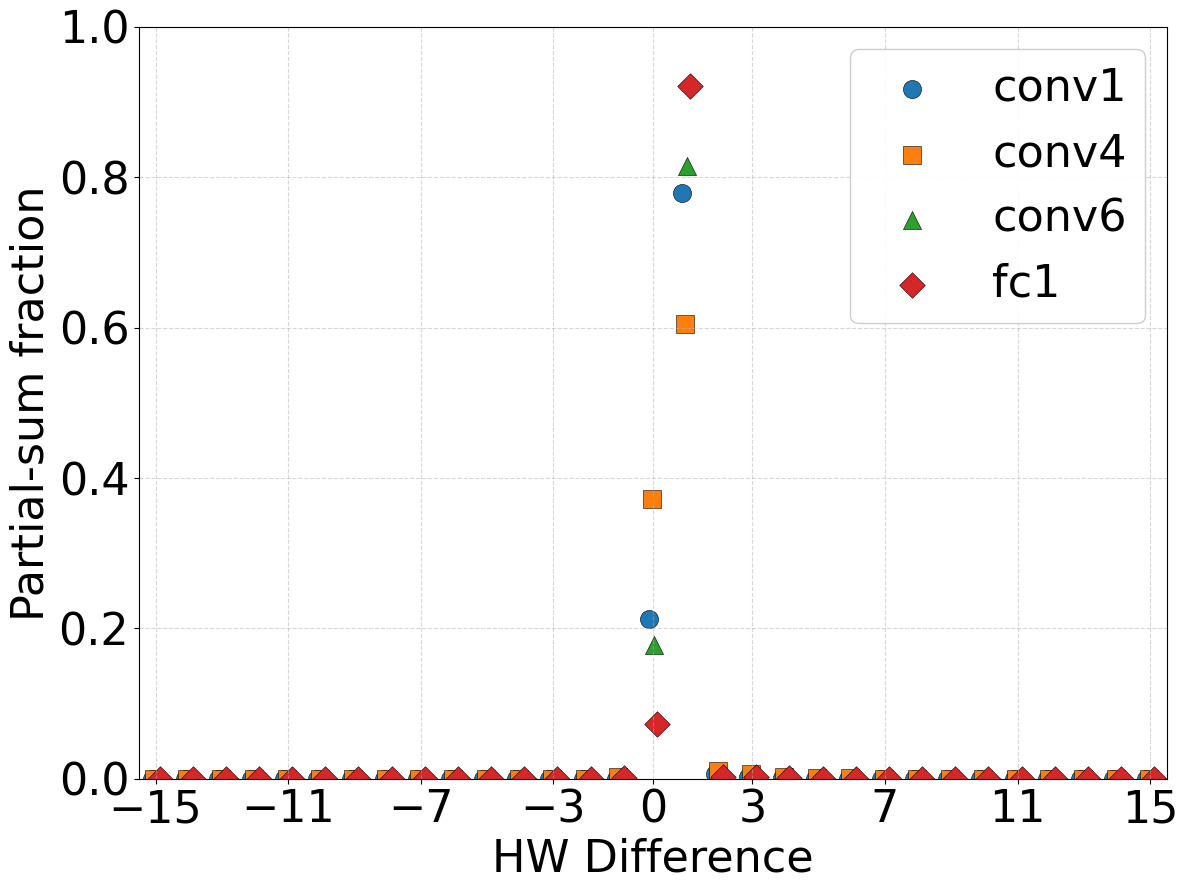

In [5]:
fig, ax, probs = plot_label_probabilities(
    res, series_labels=layers,
    xlabel="HW Difference", ylabel="Partial-sum fraction",
    figsize=(12, 9), fontsize=32, title=""
)